# 18 - Publication figures

Paper-style figures for the thesis, produced read-only from the existing data pipeline. This notebook does **not** modify any file under `data/`, `models/`, `scripts/`, `pinch_analysis/`, or any other notebook -- it only writes PDF figures to `out/figs/`.

**Part 1** recreates a representative subset of the exploratory/descriptive figures already produced by the `11`-`15` pipeline, redrawn in a consistent paper style. **Part 2** adds new figures analysing the experiment's free variables and comparing the raw vs. cleaned datasets, using `data/epoch_dataset_filtered`'s per-epoch metadata (plus `data/epoch_dataset` for the before/after-cleaning comparison).

Style rules applied to every figure below: vector PDF output; figures are drawn at their printed size -- single-column at `figsize=(COL_W, h)` (3.34 in, `\widthnarrow`), full-width at `figsize=(TEXT_W, h)` (7.09 in, `\textwidth`), from `paper_style.py` -- so LaTeX never rescales them; 7pt light sans-serif type (Roboto Light) with 7.5pt titles and 6pt legends, enforced on every saved figure; everything at column width except the SPN small multiples; the fixed 8-slot categorical palette in fixed order (never reordered, never cycled past 3 series without faceting); a light->dark blue sequential ramp for magnitude; a blue<->gray<->red diverging map centered at zero for signed/centered quantities (ERP topomaps); top/right spines dropped everywhere; thin (~0.5pt) dark bar edges; no dual y-axes; legends only for >=2 series (direct labelling otherwise).

## Setup

In [1]:
import pathlib, sys, os

ROOT = pathlib.Path.cwd()
if ROOT.name != 'DataAnalysis' and (ROOT.parent / 'DataAnalysis').exists():
    ROOT = ROOT.parent / 'DataAnalysis'
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print('Working directory:', pathlib.Path.cwd())

Working directory: C:\Users\nicol\github\VIBE\DataAnalysis


In [2]:
import json
import pickle

import mne
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from scripts.dataset_manager import read_raw_dataset

mne.set_log_level('WARNING')

RAW_DATASET = ROOT / 'data' / 'raw_dataset'
EPOCH_DATASET = ROOT / 'data' / 'epoch_dataset'              # pre-AutoReject
EPOCH_FILTERED = ROOT / 'data' / 'epoch_dataset_filtered'    # post-AutoReject (main Part-2 dataset)
RESULTS_DIR = ROOT / 'out' / 'results'
OUT_DIR = ROOT / 'out' / 'figs'
OUT_DIR.mkdir(parents=True, exist_ok=True)

def savefig(fig, name):
    enforce_font_sizes(fig)
    path = OUT_DIR / name
    fig.savefig(path)
    print('wrote', path)

### Paper style: palette, fonts, chart chrome

In [3]:
from scripts.paper_style import (COL_W, TEXT_W, CAT_COLORS, BLUE_RAMP, SEQ_CMAP, DIV_CMAP, INK_PRIMARY, INK_SECONDARY,
                         GRID_COLOR, SPINE_COLOR, clean_axes, enforce_font_sizes)

### Shared data-loading helpers

`data/raw_dataset`, `data/epoch_dataset` (pre-AutoReject) and `data/epoch_dataset_filtered` (post-AutoReject) are large (3.7GB / 2.6GB / 270MB). Where a figure only needs epoch *counts* or *metadata* (class balance, free-variable flags, session duration, marker counts) we read with `preload=False` / read the small `markers.parquet` directly, never touching the bulk numeric arrays. Only the two figures that need actual signal (grand-average ERP, topomap, peak-to-peak amplitude) load `epoch_dataset_filtered` in full, via the project's own `read_raw_dataset` (the same helper `11`-`15` use), which is small enough (~370MB once merged) to hold in memory.

In [4]:
def iter_manifest(path):
    with open(path / 'manifest.json') as f:
        manifest = json.load(f)
    for subject in sorted(manifest):
        for session in sorted(manifest[subject]):
            yield subject, session, path / subject / session


def load_raw_stats(raw_dataset_path):
    """Session duration + marker/pinch-type counts, reading only markers.parquet
    and each raw .fif file's header (preload=False) -- no signal arrays touched."""
    dur_rows, marker_rows, pinchtype_rows = [], [], []
    for subject, session, sdir in iter_manifest(raw_dataset_path):
        raw = mne.io.read_raw_fif(sdir / 'eeg_raw.fif', preload=False, verbose=False)
        dur_rows.append(dict(subject=subject, session=session,
                              duration_s=raw.times[-1] - raw.times[0]))
        markers = pd.read_parquet(sdir / 'markers.parquet')
        for et, c in markers['EventType'].value_counts().items():
            marker_rows.append(dict(subject=subject, session=session, EventType=et, count=int(c)))
        pinch = markers[markers['EventType'] == 'PinchLog']
        if len(pinch) and 'PinchType' in pinch.columns:
            for pt, c in pinch['PinchType'].value_counts().items():
                pinchtype_rows.append(dict(subject=subject, session=session, PinchType=pt, count=int(c)))
    return pd.DataFrame(dur_rows), pd.DataFrame(marker_rows), pd.DataFrame(pinchtype_rows)


def load_epoch_metadata_lazy(epoch_dataset_path):
    """Epoch metadata only (mne.read_epochs preload=False) -- counts/flags without
    loading the (for epoch_dataset, ~2.6GB of) numeric signal arrays."""
    rows = []
    for subject, session, sdir in iter_manifest(epoch_dataset_path):
        ep = mne.read_epochs(sdir / 'session-epo.fif', preload=False, verbose=False)
        m = (ep.metadata.copy() if ep.metadata is not None
             else pd.DataFrame(index=range(len(ep)))).reset_index(drop=True)
        m['subject'] = subject
        m['session'] = session
        rows.append(m)
    return pd.concat(rows, ignore_index=True)


def merge_epochs_dict(epochs_dict):
    """Concatenate the {subject: {session: Epochs}} dict into one Epochs object,
    tagging each epoch's metadata with its subject/session (same helper 11-15 use)."""
    all_epochs = []
    for subj, sessions in epochs_dict.items():
        for sess, ep in sessions.items():
            ep = ep.copy()
            n = len(ep)
            if ep.metadata is None:
                ep.metadata = pd.DataFrame({'subject': [subj] * n, 'session': [sess] * n})
            else:
                meta = ep.metadata.copy()
                meta['subject'] = subj
                meta['session'] = sess
                ep.metadata = meta
            all_epochs.append(ep)
    return mne.concatenate_epochs(all_epochs)

## Part 1: recreating the exploratory figures, in paper style

### 1a. Data-quality overview

Recreates `12_data_quality_analysis.ipynb`, cell "`plot_eeg_stats`" (also saved as `out/figs/eeg_stats_overview.png`) as four separate, individually clean figures instead of one crowded 2x2 panel. Two deviations from the original, noted here rather than silently:

1. The original's bottom-right panel ("# Bad Electrodes") reads `n_bad` from `raw.info['bads']`, which is never populated at the raw-data stage on disk (pyprep-based bad-channel detection in `12` is only ever run interactively on single example sessions, not persisted per-session) -- every cell in that panel is 0. Re-running that panel would just reproduce an all-zero heatmap, so it is replaced here with a more informative and directly comparable quality-prevalence proxy: the per-participant AutoReject epoch-rejection rate (the same rejection step `12`, cell "`autoreject_report`", performs to build `epoch_dataset_filtered`), computed cheaply from the epoch counts already on disk rather than by re-running AutoReject.
2. The original's bottom-left panel ("Mean Count per PinchType") is empty ("No PinchType data") because it filters `markers['EventType'] == 'PinchType'`, which never matches (the actual value is `'PinchLog'`). Fixed below.

In [5]:
dur_df, marker_df, pinchtype_df = load_raw_stats(RAW_DATASET)
print('sessions:', dur_df.shape[0], ' subjects:', dur_df['subject'].nunique())
all_sessions = dur_df[['subject', 'session']].drop_duplicates()

sessions: 36  subjects: 19


pre-AR epochs: 61771  post-AR epochs: 6548
wrote C:\Users\nicol\github\VIBE\DataAnalysis\out\figs\dataquality_autoreject_droprate.pdf


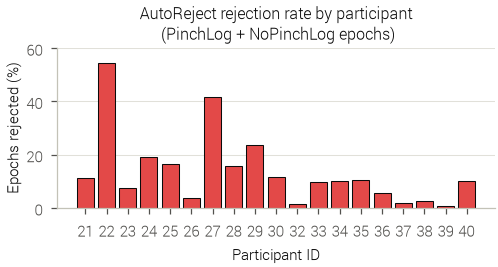

In [6]:
md_pre = load_epoch_metadata_lazy(EPOCH_DATASET)
md_post_lazy = load_epoch_metadata_lazy(EPOCH_FILTERED)
print('pre-AR epochs:', md_pre.shape[0], ' post-AR epochs:', md_post_lazy.shape[0])

pre_counts = (md_pre[md_pre['EventType'].isin(['PinchLog', 'NoPinchLog'])]
              .groupby('subject').size().rename('n_pre'))
post_counts = md_post_lazy.groupby('subject').size().rename('n_post')
cmp_df = pd.concat([pre_counts, post_counts], axis=1).fillna(0)
cmp_df['drop_rate'] = 1 - cmp_df['n_post'] / cmp_df['n_pre']
cmp_df = cmp_df.sort_index(key=lambda s: [int(x.split('_')[1]) for x in s])

fig, ax = plt.subplots(figsize=(COL_W, 1.8))
x = np.arange(len(cmp_df))
ax.bar(x, cmp_df['drop_rate'] * 100, color=CAT_COLORS[7], edgecolor=INK_PRIMARY, linewidth=0.5)
ax.set_xticks(x)
ax.set_xticklabels([s.replace('subject_', '') for s in cmp_df.index])
ax.set_xlabel('Participant ID')
ax.set_ylabel('Epochs rejected (%)')
ax.set_ylim(0,60)
ax.set_title('AutoReject rejection rate by participant\n (PinchLog + NoPinchLog epochs)')
ax.yaxis.grid(True)
ax.set_axisbelow(True)
clean_axes(ax)
fig.tight_layout(pad=0.3)
savefig(fig, 'dataquality_autoreject_droprate.pdf')
plt.show()

### 1b. Grand-average ERP and topomap sequence

Loads the full `data/epoch_dataset_filtered` (post-AutoReject) with signal data via the project's own `read_raw_dataset` + `merge_epochs_dict` -- the same pattern `12`/`13`/`15` use -- and applies the same channel-wise mean-normalization step `13_free_variable_comparison.ipynb` applies before plotting from this dataset. This merged, normalized `epochs` object (and its `.metadata` as `md`) is reused for every remaining figure in this notebook, including all of Part 2.

All figures that plot signal amplitudes (the ERP curves, the topomap sequence, the SPN small multiples and the layout ERP) use `epochs_hp`, a copy of `epochs` passed through a **1 Hz high-pass filter** (zero-phase 4th-order Butterworth, applied forward and backward). An FIR filter is not used because at 1 Hz it would be longer (3.3 s) than the 2 s epochs. Note that a 1 Hz high-pass also attenuates slow cortical potentials such as the Bereitschaftspotential and the SPN, whose energy lies mostly below 1 Hz. The epoch counts and the peak-to-peak amplitude figure use the unfiltered `epochs`.

In [7]:
epochs_dict = read_raw_dataset(EPOCH_FILTERED)
epochs = merge_epochs_dict(epochs_dict)
epochs.apply_function(lambda x: (x - x.mean()), channel_wise=True)  # matches 13's own normalization

# 1 Hz high-pass for all signal (ERP/topomap) figures. Epochs are only 2 s long (601 samples), shorter
# than the 3.3 s an FIR high-pass at 1 Hz needs, so a zero-phase Butterworth IIR is used instead.
HP_FREQ = 1.0
epochs_hp = epochs.copy().filter(l_freq=HP_FREQ, h_freq=None, method='iir', verbose=False)

md = epochs.metadata
times = epochs.times
n_subjects = md['subject'].nunique()
print(epochs)
print(f'{n_subjects} participants, tmin={epochs.tmin}s, tmax={epochs.tmax}s')

C:\Users\nicol\AppData\Local\Temp\ipykernel_20276\4017154873.py:57: RuntimeWarning: Concatenation of Annotations within Epochs is not supported yet. All annotations will be dropped.
  return mne.concatenate_epochs(all_epochs)


<EpochsArray | 6548 events (all good), -1.7 – 0.3 s (baseline -1.7 – 0 s), ~630.5 MiB, data loaded, with metadata,
 'PinchLog': 3645
 'NoPinchLog': 2903>
19 participants, tmin=-1.7s, tmax=0.3s


**Figure: grand-average ERP, Pinch vs. No-Pinch, at C3, Cz and C4.** Mean epoch amplitude after a 1 Hz high-pass (shaded band = +/-1 SEM across epochs) time-locked to pinch completion (t=0), for true `PINCH` trials with full, undelayed feedback (visual and auditory feedback and virtual hand all present, `feedbackIsDelayed` false), and for choice `PINCH` trials without feedback delay (choice trials never show the virtual hand, so for them only the no-delay condition is applied) vs. `NoPinchLog` control epochs, at three motor-relevant electrodes. With the slow (<1 Hz) components removed, the slow pre-movement negativity is largely suppressed; what remains is a short negative deflection at C3/Cz just before and after t=0 that is absent for the no-pinch control. No-Pinch epochs stay close to zero throughout, as expected.

*Based on: `13_free_variable_comparison.ipynb`, cell `plot_compare_evokeds_grid(..., group_by="EventType")` ("Pinch vs No Pinch" section) -- redrawn as a compact 3-channel comparison instead of the full 20-channel grid.*

n_pinch 865 n_nopinch 2903 n_pinch_choice 272
wrote C:\Users\nicol\github\VIBE\DataAnalysis\out\figs\erp_pinch_vs_nopinch.pdf


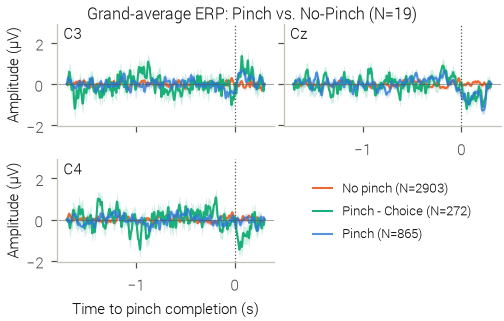

In [8]:
picks = ['C3', 'Cz', 'C4']
# pinches with full feedback only: visual + auditory feedback + virtual hand, none delayed
# (flags are None/NaN on NoPinchLog epochs, hence the explicit == True / == False)
mask_full_fb = ((md['hasVisualFeedback'] == True) & (md['hasAuditoryFeedback'] == True)
                & (md['hasVirtualHand'] == True) & (md['feedbackIsDelayed'] == False)).values
mask_pinch = ((md['EventType'] == 'PinchLog') & (md['PinchType'] == 'PINCH')).values & mask_full_fb
mask_nopinch = (md['EventType'] == 'NoPinchLog').values
# choice trials never show the virtual hand, so they cannot meet mask_full_fb; keep only the no-delay condition for them
mask_pinch_choice = ((md['EventType'] == 'PinchLog') & (md['PinchType'] == 'PINCH') & (md['isChoiceStimuli'] == True)
                     & (md['feedbackIsDelayed'] == False)).values
n_pinch, n_nopinch, n_pinch_choice = int(mask_pinch.sum()), int(mask_nopinch.sum()), int(mask_pinch_choice.sum())
print('n_pinch', n_pinch, 'n_nopinch', n_nopinch, 'n_pinch_choice', n_pinch_choice)

data_erp = epochs_hp.get_data(picks=picks) * 1e6  # volts -> microvolts

fig, axes = plt.subplots(2, 2, figsize=(COL_W, 2.1), sharex=True, sharey=True, layout='constrained')
fig.get_layout_engine().set(h_pad=0, w_pad=0.01, hspace=0, wspace=0)  # dense: minimal padding between panels
axes = axes.ravel()
groups = {f'No pinch (N={n_nopinch})': (mask_nopinch, CAT_COLORS[1], 1), f'Pinch - Choice (N={n_pinch_choice})': (mask_pinch_choice, CAT_COLORS[2], 1), f'Pinch (N={n_pinch})': (mask_pinch, CAT_COLORS[0], 0.8)}
for ax, ch in zip(axes, picks):
    for label, (mask, color, alpha) in groups.items():
        d = data_erp[mask, picks.index(ch), :]
        m = d.mean(axis=0)
        sem = d.std(axis=0, ddof=1) / np.sqrt(d.shape[0])
        ax.plot(times, m, color=color, linewidth=1, label=label, alpha=alpha)
        ax.fill_between(times, m - sem, m + sem, color=color, alpha=0.2, linewidth=0)
    ax.axvline(0, color=INK_SECONDARY, linewidth=0.6, linestyle=':')
    ax.axhline(0, color=INK_SECONDARY, linewidth=0.5, alpha=0.5)
    ax.text(0.03, 1.0, ch, transform=ax.transAxes, ha='left', va='top', color=INK_PRIMARY)  # in-panel label, no title row
    clean_axes(ax)
lo, hi = axes[0].get_ylim()
axes[0].set_ylim(lo, hi + 0.25 * (hi - lo))  # headroom for the in-panel channel labels (y is shared)
axes[0].set_ylabel('Amplitude (\u00b5V)')
axes[2].set_ylabel('Amplitude (\u00b5V)')
axes[2].set_xlabel('Time to pinch completion (s)')
axes[1].tick_params(labelbottom=True)  # the panel below it holds the legend
axes[-1].set_axis_off()
handles, labels = axes[0].get_legend_handles_labels()
axes[-1].legend(handles, labels, loc='center', frameon=False)
fig.suptitle(f'Grand-average ERP: Pinch vs. No-Pinch (N={n_subjects})')
savefig(fig, 'erp_pinch_vs_nopinch.pdf')
plt.show()

n_pinch 2623 n_wizard_of_oz 611
wrote C:\Users\nicol\github\VIBE\DataAnalysis\out\figs\erp_pinch_vs_hinted.pdf


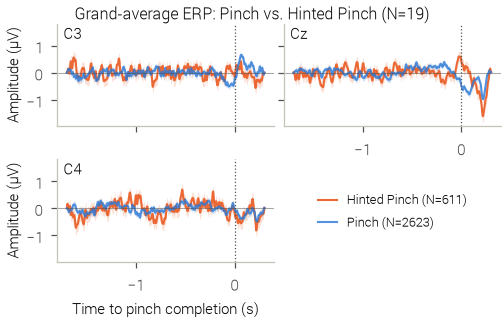

In [9]:
picks = ['C3', 'Cz', 'C4']
mask_pinch = ((md['EventType'] == 'PinchLog') & (md['PinchType'] == 'PINCH')).values
mask_hinted = ((md['EventType'] == 'PinchLog') & (md['PinchType'] == 'PINCH_WIZARD_OF_OZ')).values
n_pinch, n_hinted = int(mask_pinch.sum()), int(mask_hinted.sum())
print('n_pinch', n_pinch, 'n_wizard_of_oz', n_hinted)

data_erp = epochs_hp.get_data(picks=picks) * 1e6  # volts -> microvolts

fig, axes = plt.subplots(2, 2, figsize=(COL_W, 2.1), sharex=True, sharey=True, layout='constrained')
fig.get_layout_engine().set(h_pad=0, w_pad=0.01, hspace=0, wspace=0)  # dense: minimal padding between panels
axes = axes.ravel()
groups = {f'Hinted Pinch (N={n_hinted})': (mask_hinted, CAT_COLORS[1], 1), f'Pinch (N={n_pinch})': (mask_pinch, CAT_COLORS[0], 0.8)}
for ax, ch in zip(axes, picks):
    for label, (mask, color, alpha) in groups.items():
        d = data_erp[mask, picks.index(ch), :]
        m = d.mean(axis=0)
        sem = d.std(axis=0, ddof=1) / np.sqrt(d.shape[0])
        ax.plot(times, m, color=color, linewidth=1, label=label, alpha=alpha)
        ax.fill_between(times, m - sem, m + sem, color=color, alpha=0.2, linewidth=0)
    ax.axvline(0, color=INK_SECONDARY, linewidth=0.6, linestyle=':')
    ax.axhline(0, color=INK_SECONDARY, linewidth=0.5, alpha=0.5)
    ax.text(0.03, 1.0, ch, transform=ax.transAxes, ha='left', va='top', color=INK_PRIMARY)  # in-panel label, no title row
    clean_axes(ax)
lo, hi = axes[0].get_ylim()
axes[0].set_ylim(lo, hi + 0.25 * (hi - lo))  # headroom for the in-panel channel labels (y is shared)
axes[0].set_ylabel('Amplitude (\u00b5V)')
axes[2].set_ylabel('Amplitude (\u00b5V)')
axes[2].set_xlabel('Time to pinch completion (s)')
axes[1].tick_params(labelbottom=True)  # the panel below it holds the legend
axes[-1].set_axis_off()
handles, labels = axes[0].get_legend_handles_labels()
axes[-1].legend(handles, labels, loc='center', frameon=False)
fig.suptitle(f'Grand-average ERP: Pinch vs. Hinted Pinch (N={n_subjects})')
savefig(fig, 'erp_pinch_vs_hinted.pdf')
plt.show()

**Figure: topomap sequence, PINCH trials.** Scalp distribution of the grand-average PINCH-trial ERP at five timepoints from -0.6s to +0.2s around pinch onset, diverging colormap centered at 0ÂµV (blue = negative, red = positive). A central negativity emerges and peaks close to t=0, spatially consistent with the C3/Cz time-course above.

*Based on: `13_free_variable_comparison.ipynb`, cell `plot_joint_grouped(..., group_by="EventType")` ("Pinch vs No Pinch" section, topomap-sequence part of `ev.plot_joint`) -- redrawn as a standalone topomap strip (the joint line plot is covered by the ERP figure above) with the diverging palette in place of the default colormap.*

wrote C:\Users\nicol\github\VIBE\DataAnalysis\out\figs\topomap_pinch_sequence.pdf


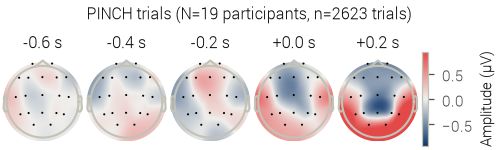

In [10]:
ev_pinch = epochs_hp[mask_pinch].average()
ref_chs = [c for c in ev_pinch.ch_names if c not in ('A1', 'A2')]  # drop mastoid refs from the scalp map
ev_topo = ev_pinch.copy().pick(ref_chs)

show_times = [t for t in [-0.6, -0.4, -0.2, 0.0, 0.2] if ev_topo.tmin <= t <= ev_topo.tmax]
sel_idx = [np.argmin(np.abs(ev_topo.times - t)) for t in show_times]
topo_data = ev_topo.data * 1e6
vmax = np.abs(topo_data[:, sel_idx]).max()

fig, axes = plt.subplots(1, len(show_times) + 1, figsize=(COL_W, 1),
                          gridspec_kw={'width_ratios': [1] * len(show_times) + [0.08]})
for ax, idx, t in zip(axes[:-1], sel_idx, show_times):
    im, _ = mne.viz.plot_topomap(
        topo_data[:, idx], ev_topo.info, axes=ax, show=False,
        cmap=DIV_CMAP, vlim=(-vmax, vmax), sensors=True, contours=0,
    )
    ax.set_title(f'{t:+.1f} s')
cbar = fig.colorbar(im, cax=axes[-1])
cbar.set_label('Amplitude (\u00b5V)')
fig.suptitle(f'PINCH trials (N={n_subjects} participants, n={n_pinch} trials)')
fig.tight_layout(pad=0.3, rect=[0, 0, 1, 0.86])
savefig(fig, 'topomap_pinch_sequence.pdf')
plt.show()

### 1c. Model comparison across evaluation splits

Reads the cached LOSO summary already computed for the thesis (`out/model_metrics_loso.csv`, produced from `out/results/{rf,eegnet,transformer}_leave_one_out_run.pkl` -- see `17_feedback_and_significance_analysis.ipynb`) for the Leave-One-Out bars, and loads only the small `general_run`/`cross_session_run` result pickles directly for the Mixed and Cross-Session bars, avoiding the 200-360MB `leave_one_out_run.pkl` files.

**Figure: pinch-detection accuracy by model and evaluation split.** Test accuracy for the three models (RandomForest/EEGForest, EEGNet, GAT-GRU-Transformer) under a mixed (in-distribution) split, leave-one-subject-out cross-validation, and a cross-session split, with the majority-class chance level (from the LOSO confusion matrices) as a reference line. EEGNet is the strongest and most consistent model across all three splits; leave-one-out and cross-session accuracy are both noticeably lower than the mixed split for every model, showing that subject- and session-generalization is harder than in-distribution classification.

*Based on: `16_results_analysis.ipynb`, cell `plot_overall_performance_comparison` ("model comparison - overall").*

In [11]:
from models.EEGNet import EEGNet, ConstrainedConv2d, ConstrainedLinear
from models.GATGRU import MultiBranchGATGRUTransformer, SpatialBranch, FrequencyBranch, TemporalBranch, GATLayer

def load_cached(name):
    with open(RESULTS_DIR / f'{name}.pkl', 'rb') as fh:
        cached = pickle.load(fh)
    return cached['result']

rf_general, _ = load_cached('rf_general_run')
rf_cross_session, _ = load_cached('rf_cross_session_run')
eegnet_general, _ = load_cached('eegnet_general_run')
eegnet_cross_session, _ = load_cached('eegnet_cross_session_run')
transformer_general = load_cached('transformer_general_run')
transformer_cross_session, _ = load_cached('transformer_cross_session_run')

loso_csv = pd.read_csv(OUT_DIR.parent / 'model_metrics_loso.csv')
loso_csv

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from C:\Users\nicol\_netrc.
wandb: Currently logged in as: nbaeriswyl (nbaeriswyl-eth-z-rich) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


,model,accuracy_mean,accuracy_std,pooled_accuracy,precision,recall,f1,fpr,chance_mean,n_pooled,tp,fn,fp,tn
0,RF,0.635471,0.051566,0.641183,0.640828,0.601982,0.620798,0.321467,0.531375,5376,1579,1044,885,1868
1,EEGNet,0.700328,0.058001,0.697731,0.698331,0.669844,0.683791,0.275699,0.531375,5376,1757,866,759,1994
2,Transformer,0.635031,0.065402,0.631696,0.610367,0.677850,0.642341,0.412278,0.531375,5376,1778,845,1135,1618


wrote C:\Users\nicol\github\VIBE\DataAnalysis\out\figs\model_comparison_by_split.pdf


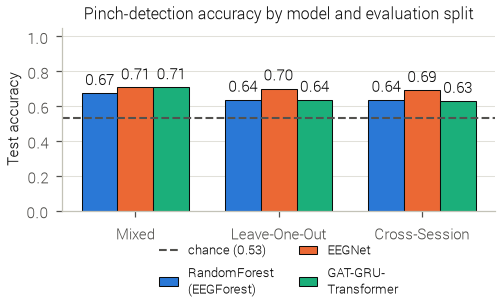

In [12]:
model_names = ['RF', 'EEGNet', 'Transformer']
pretty = {'RF': 'RandomForest\n(EEGForest)', 'EEGNet': 'EEGNet', 'Transformer': 'GAT-GRU-\nTransformer'}
splits = ['Mixed', 'Leave-One-Out', 'Cross-Session']

acc = {
    'RF': [rf_general['test_accuracy'],
           loso_csv.loc[loso_csv.model == 'RF', 'accuracy_mean'].item(),
           rf_cross_session['test_accuracy']],
    'EEGNet': [eegnet_general['test_accuracy'],
               loso_csv.loc[loso_csv.model == 'EEGNet', 'accuracy_mean'].item(),
               eegnet_cross_session['test_accuracy']],
    'Transformer': [transformer_general['test_accuracy'],
                    loso_csv.loc[loso_csv.model == 'Transformer', 'accuracy_mean'].item(),
                    transformer_cross_session['test_accuracy']],
}
chance_loso = loso_csv['chance_mean'].iloc[0]

fig, ax = plt.subplots(figsize=(COL_W, 2.1))
x = np.arange(len(splits))
width = 0.25
for i, m in enumerate(model_names):
    bars = ax.bar(x + (i - 1) * width, acc[m], width, color=CAT_COLORS[i],
                   edgecolor=INK_PRIMARY, linewidth=0.5, label=pretty[m])
    ax.bar_label(bars, fmt='%.2f', padding=2)
ax.axhline(chance_loso, color=INK_SECONDARY, linestyle='--', linewidth=1,
           label=f'chance ({chance_loso:.2f})')
ax.set_xticks(x)
ax.set_xticklabels(splits)
ax.set_ylabel('Test accuracy')
ax.set_ylim(0, 1.05)
ax.set_title('Pinch-detection accuracy by model and evaluation split')
ax.legend(frameon=False, loc='upper center', ncol=2, bbox_to_anchor=(0.5, -0.12))
ax.yaxis.grid(True)
ax.set_axisbelow(True)
clean_axes(ax)
fig.tight_layout(pad=0.3)
savefig(fig, 'model_comparison_by_split.pdf')
plt.show()

## Part 2: free-variable and dataset analysis

New figures (not recreations), built from `epochs`/`md` loaded above (`data/epoch_dataset_filtered`, post-AutoReject). Confirmed metadata columns for the free variables: `hasVisualFeedback`, `hasAuditoryFeedback`, `hasVirtualHand`, `feedbackIsDelayed`, `pinchIsHinted`, `isChoiceStimuli` (all boolean, `None`/NaN on `NoPinchLog` epochs where they're undefined) and `numberOfStimuli` (a 3-way categorical stimulus-layout size: 1, 4, or 6 stimuli), plus `subject` and `session` as the subject/session identifiers added by `merge_epochs_dict`. All free-variable and stimulus-layout figures below are restricted to real `PINCH` trials (`EventType == 'PinchLog' & PinchType == 'PINCH'`), the only epochs on which every flag is defined.

In [13]:
FREE_VARS = ['hasVisualFeedback', 'hasAuditoryFeedback', 'hasVirtualHand',
             'feedbackIsDelayed', 'pinchIsHinted', 'isChoiceStimuli']
PRETTY = {
    'hasVisualFeedback': 'Visual feedback',
    'hasAuditoryFeedback': 'Auditory feedback',
    'hasVirtualHand': 'Virtual hand',
    'feedbackIsDelayed': 'Delayed feedback',
    'pinchIsHinted': 'Pinch hinted',
    'isChoiceStimuli': 'Choice stimuli',
}

pinch_mask = ((md['EventType'] == 'PinchLog') & (md['PinchType'] == 'PINCH')).values
ch = 'C3'
data_c3 = epochs_hp.get_data(picks=[ch])[:, 0, :] * 1e6  # (n_epochs, n_times), microvolts

**Figure: feedback free variables at the SPN electrodes where each feedback modality enlarges the SPN (small multiples).** Grand-average ERP (+/-1 SEM, 1 Hz high-passed) for flag=True vs. flag=False, restricted to real PINCH trials, for the three feedback variables (visual feedback, auditory feedback, virtual hand). Candidate electrodes are the 15 on which the stimulus-preceding negativity (SPN) is typically recorded (Brunia & van Boxtel 2001; Böcker et al. 1994; the same `SPN` set used for the SPN features in `models/EEGForest.py`). Each modality's row shows **its own** electrode set: the electrodes where the SPN is larger *with* that modality than without it, ordered by the size of that increase (largest first, left to right) and capped at the five largest (`SPN_MAX_CHS`), so the rows show different electrodes and possibly a different number of panels. "Larger SPN" means a mean amplitude in the late SPN window (-0.2 to 0 s before the pinch, shaded; the same late window `spn_features` uses) that is at least 0.1 µV more negative with the modality (`SPN_MIN_EFFECT`), so near-zero differences do not count. All panels share one y-axis.

The selection is a descriptive filter on grand averages, not a statistical test, and it depends on both the window and the filtering: the SPN is a slow potential, so the 1 Hz high-pass removes much of it and changes which electrodes pass. The per-electrode True-minus-False differences are printed below the figure code for reference.

True - False mean amplitude in (-0.2, 0.0) s (µV; negative = larger SPN with the modality):
    hasVisualFeedback  hasAuditoryFeedback  hasVirtualHand
F7              0.111               -0.082           0.211
F3             -0.047               -0.074           0.123
Fz              0.038               -0.190           0.037
F4              0.077               -0.268           0.019
F8              0.219               -0.227           0.082
T7             -0.098                0.095           0.035
C3             -0.112                0.028          -0.102
Cz             -0.043                0.010           0.037
C4             -0.105                0.082           0.027
T8             -0.228                0.124          -0.113
P7             -0.409                0.111          -0.118
P3             -0.102                0.063           0.027
Pz             -0.063                0.091           0.012
P4             -0.110               -0.067          -0.044
P8             -0.243  

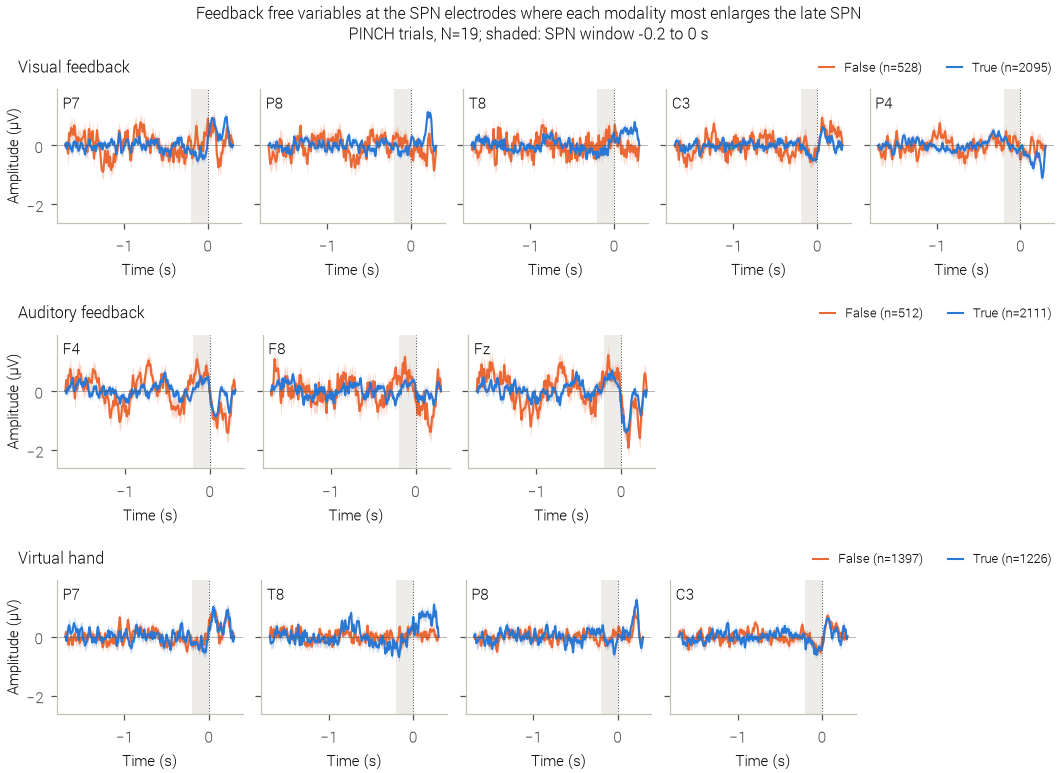

In [25]:
SPN_GRID = [['F7', 'F3', 'Fz', 'F4', 'F8'],
            ['T7', 'C3', 'Cz', 'C4', 'T8'],
            ['P7', 'P3', 'Pz', 'P4', 'P8']]
SPN_VARS = ['hasVisualFeedback', 'hasAuditoryFeedback', 'hasVirtualHand']
SPN_WINDOW = (-0.2, 0.0)  # late SPN window, s relative to the pinch (same as spn_features)
SPN_MIN_EFFECT = 0.1  # µV, smallest True - False difference that counts as a larger SPN
SPN_MAX_CHS = 5  # at most this many electrodes per feedback modality, largest SPN increase first

spn_chs = [c for row in SPN_GRID for c in row]  # scalp order: frontal -> parietal, left -> right
data_spn = epochs_hp.get_data(picks=spn_chs) * 1e6  # (n_epochs, 15, n_times), microvolts
win_mask = (times >= SPN_WINDOW[0]) & (times <= SPN_WINDOW[1])

# SPN amplitude = mean amplitude in the late window; "larger SPN" = more negative, so an electrode
# is shown in a modality's row if True - False <= -SPN_MIN_EFFECT for that modality; the row keeps
# the SPN_MAX_CHS electrodes with the most negative difference, ordered most negative first
masks = {var: (pinch_mask & (md[var].values == True), pinch_mask & (md[var].values == False))
         for var in SPN_VARS}
spn_diff = pd.DataFrame({
    var: data_spn[m_t][:, :, win_mask].mean((0, 2)) - data_spn[m_f][:, :, win_mask].mean((0, 2))
    for var, (m_t, m_f) in masks.items()
}, index=spn_chs)
print(f'True - False mean amplitude in {SPN_WINDOW} s (µV; negative = larger SPN with the modality):')
print(spn_diff.round(3).to_string())
sel_chs = {var: spn_diff[var][spn_diff[var] <= -SPN_MIN_EFFECT].sort_values().index[:SPN_MAX_CHS].tolist()
           for var in SPN_VARS}
print()
for var, chs in sel_chs.items():
    print(f'selected electrodes for {var}: ' + ', '.join(f'{c} ({spn_diff.at[c, var]:.3f})' for c in chs))
if not any(sel_chs.values()):
    raise ValueError(f'no SPN electrode shows a larger SPN (>= {SPN_MIN_EFFECT} µV) with '
                     f'any feedback modality in {SPN_WINDOW}')

def mean_sem(d):
    return d.mean(0), d.std(0, ddof=1) / np.sqrt(d.shape[0])

spn_lines = {}
y_lo, y_hi = np.inf, -np.inf
for var, (m_t, m_f) in masks.items():
    for c in sel_chs[var]:
        ci = spn_chs.index(c)
        (mt, st), (mf, sf) = mean_sem(data_spn[m_t, ci]), mean_sem(data_spn[m_f, ci])
        spn_lines[var, c] = (mt, st, mf, sf)
        y_lo = min(y_lo, (mt - st).min(), (mf - sf).min())
        y_hi = max(y_hi, (mt + st).max(), (mf + sf).max())
pad = 0.1 * (y_hi - y_lo)

# one panel row per modality with the same column count everywhere, so panels have equal widths
n_cols = max(len(chs) for chs in sel_chs.values())
fig = plt.figure(figsize=(TEXT_W, 0.4 + len(SPN_VARS) * 1.6), layout='constrained')
subfigs = np.atleast_1d(fig.subfigures(len(SPN_VARS), 1, hspace=0.04))
for sf_, var in zip(subfigs, SPN_VARS):
    # identical y-limits are set on every panel below, so the scale is shared across modalities too
    axes = np.atleast_2d(sf_.subplots(1, n_cols, sharex=True, sharey=True, squeeze=False))
    n_t, n_f = int(masks[var][0].sum()), int(masks[var][1].sum())
    chs = sel_chs[var]
    if not chs:
        for ax in axes.ravel():
            ax.set_axis_off()
        axes[0, 0].text(0, 0.5, f'no electrode with a larger SPN (≥ {SPN_MIN_EFFECT:g} µV)',
                        transform=axes[0, 0].transAxes, ha='left', va='center', color=INK_SECONDARY)
        sf_.suptitle(PRETTY[var], x=0.02, ha='left')
        continue
    for i, ax in enumerate(axes.ravel()):
        if i >= len(chs):
            ax.set_axis_off()
            continue
        c = chs[i]
        mt, st, mf, sf = spn_lines[var, c]
        ax.axvspan(*SPN_WINDOW, color=GRID_COLOR, alpha=0.6, linewidth=0)
        ax.plot(times, mf, color=CAT_COLORS[1], linewidth=1.0, label=f'False (n={n_f})')
        ax.fill_between(times, mf - sf, mf + sf, color=CAT_COLORS[1], alpha=0.25, linewidth=0)
        ax.plot(times, mt, color=CAT_COLORS[0], linewidth=1.0, label=f'True (n={n_t})')
        ax.fill_between(times, mt - st, mt + st, color=CAT_COLORS[0], alpha=0.25, linewidth=0)
        ax.axvline(0, color=INK_SECONDARY, linewidth=0.5, linestyle=':')
        ax.axhline(0, color=INK_SECONDARY, linewidth=0.4, alpha=0.5)
        ax.set_ylim(y_lo - pad, y_hi + pad)
        ax.text(0.03, 0.97, c, transform=ax.transAxes, ha='left', va='top', color=INK_PRIMARY)
        clean_axes(ax)
        ax.set_xlabel('Time (s)')
    for ax in axes[:, 0]:
        ax.set_ylabel('Amplitude (µV)')
    handles, labels = axes[0, 0].get_legend_handles_labels()
    sf_.suptitle(PRETTY[var], x=0.02, ha='left')
    sf_.legend(handles, labels, loc='upper right', ncol=2, frameon=False, handlelength=1.2)

fig.suptitle(f'Feedback free variables at the SPN electrodes where each modality most enlarges the late SPN\n'
             f'PINCH trials, N={n_subjects}; shaded: SPN window {SPN_WINDOW[0]:g} to {SPN_WINDOW[1]:g} s')
savefig(fig, 'freevar_erp_spn_smallmultiples.pdf')
plt.show()


**Figure: class balance of the boolean free variables.** Epoch counts for True vs. False for each free variable (PINCH trials only, N=15 participants). Visual/auditory feedback are present on ~80% of trials; virtual hand is roughly balanced; delayed feedback, hinting and choice stimuli are all deliberately rare manipulations (10-24% True), so their ERP averages rest on far fewer trials than the feedback variables'.

wrote C:\Users\nicol\github\VIBE\DataAnalysis\out\figs\freevar_epoch_counts.pdf


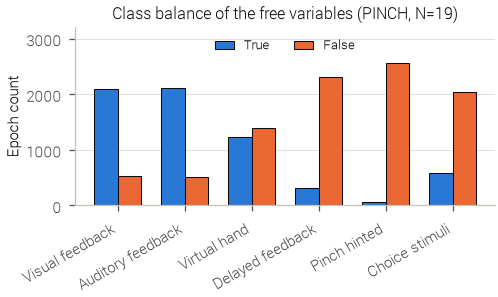

In [15]:
fig, ax = plt.subplots(figsize=(COL_W, 2))
x = np.arange(len(FREE_VARS))
width = 0.35
counts_true = [int((pinch_mask & (md[v].values == True)).sum()) for v in FREE_VARS]
counts_false = [int((pinch_mask & (md[v].values == False)).sum()) for v in FREE_VARS]
ax.bar(x - width / 2, counts_true, width, color=CAT_COLORS[0], edgecolor=INK_PRIMARY, linewidth=0.5, label='True')
ax.bar(x + width / 2, counts_false, width, color=CAT_COLORS[1], edgecolor=INK_PRIMARY, linewidth=0.5, label='False')
ax.set_xticks(x)
ax.set_xticklabels([PRETTY[v] for v in FREE_VARS], rotation=30, ha='right')
ax.set_ylabel('Epoch count')
ax.set_title(f'Class balance of the free variables (PINCH, N={n_subjects})')
ax.set_ylim(top=max(counts_true + counts_false) * 1.25)  # room for the legend
ax.legend(frameon=False, loc='upper center', ncols=2)
ax.yaxis.grid(True)
ax.set_axisbelow(True)
clean_axes(ax)
fig.tight_layout(pad=0.3)
savefig(fig, 'freevar_epoch_counts.pdf')
plt.show()

**Figure: stimulus-layout size (numberOfStimuli).** Left: epoch count for each of the three stimulus-layout sizes (1/4/6 candidate stimuli on screen). Right: grand-average C3 ERP for the same three groups. The 4- and 6-stimulus layouts (the two "real" multi-target conditions) track each other closely; the 1-stimulus layout (trivial/no-choice trials, smallest n) is visibly noisier and diverges most from baseline, consistent with it being the least-sampled condition.

wrote C:\Users\nicol\github\VIBE\DataAnalysis\out\figs\numberofstimuli_layout.pdf


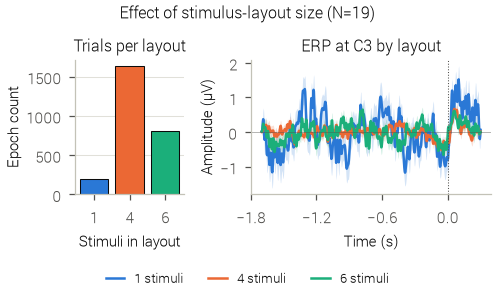

In [16]:
levels = sorted(md.loc[pinch_mask, 'numberOfStimuli'].dropna().unique())

fig, axes = plt.subplots(1, 2, figsize=(COL_W, 2.0), layout='constrained', gridspec_kw={'width_ratios': [1, 2.2]})
ax = axes[0]
level_counts = [int((pinch_mask & (md['numberOfStimuli'] == lv)).sum()) for lv in levels]
ax.bar([str(int(lv)) for lv in levels], level_counts, color=CAT_COLORS[:len(levels)],
       edgecolor=INK_PRIMARY, linewidth=0.5)
ax.set_xlabel('Stimuli in layout')
ax.set_ylabel('Epoch count')
ax.set_title('Trials per layout')
ax.yaxis.grid(True)
ax.set_axisbelow(True)
clean_axes(ax)

ax = axes[1]
for i, lv in enumerate(levels):
    m = pinch_mask & (md['numberOfStimuli'] == lv)
    d = data_c3[m]
    mean_, sem_ = d.mean(0), d.std(0, ddof=1) / np.sqrt(d.shape[0])
    ax.plot(times, mean_, color=CAT_COLORS[i], linewidth=1.2, label=f'{int(lv)} stimuli')
    ax.fill_between(times, mean_ - sem_, mean_ + sem_, color=CAT_COLORS[i], alpha=0.2, linewidth=0)
ax.axvline(0, color=INK_SECONDARY, linewidth=0.5, linestyle=':')
ax.axhline(0, color=INK_SECONDARY, linewidth=0.4, alpha=0.5)
ax.set_xlabel('Time (s)')
ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(4))
ax.set_ylabel('Amplitude (\u00b5V)')
ax.set_title(f'ERP at {ch} by layout')
fig.legend(*ax.get_legend_handles_labels(), frameon=False, loc='outside lower center', ncols=len(levels))
clean_axes(ax)
fig.suptitle(f'Effect of stimulus-layout size (N={n_subjects})')
savefig(fig, 'numberofstimuli_layout.pdf')
plt.show()

### Dataset comparisons

**Figure: session 1 vs. session 2.** Left: total epoch count. Right: class balance (share of `PinchLog` vs. `NoPinchLog` epochs). Session 1 contributes more than twice as many epochs as session 2 (consistent with its longer duration, see the data-quality section), but the Pinch/No-Pinch class balance is essentially unchanged between sessions.

wrote C:\Users\nicol\github\VIBE\DataAnalysis\out\figs\dataset_session1_vs_session2.pdf


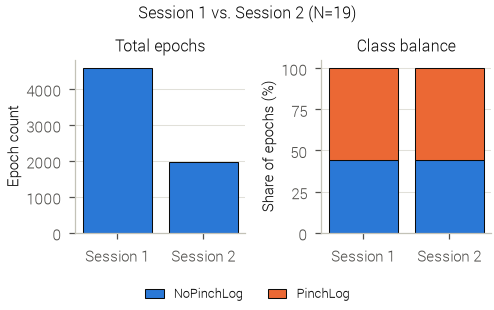

In [17]:
sess_counts = md.groupby('session').size()
sess_class = md.groupby(['session', 'EventType']).size().unstack(fill_value=0)
sess_class_frac = sess_class.div(sess_class.sum(axis=1), axis=0)

fig, axes = plt.subplots(1, 2, figsize=(COL_W, 2.1), layout='constrained')
ax = axes[0]
ax.bar(sess_counts.index.str.replace('session_', 'Session '), sess_counts.values,
       color=CAT_COLORS[0], edgecolor=INK_PRIMARY, linewidth=0.5)
ax.set_ylabel('Epoch count')
ax.set_title('Total epochs')
ax.yaxis.grid(True)
ax.set_axisbelow(True)
clean_axes(ax)

ax = axes[1]
sess_labels = sess_class_frac.index.str.replace('session_', 'Session ')
bottom = np.zeros(len(sess_class_frac))
for i, evtype in enumerate(sess_class_frac.columns):
    vals = sess_class_frac[evtype].values * 100
    ax.bar(sess_labels, vals, bottom=bottom, color=CAT_COLORS[i], edgecolor=INK_PRIMARY,
           linewidth=0.5, label=evtype)
    bottom += vals
ax.set_ylabel('Share of epochs (%)')
ax.set_title('Class balance')
ax.yaxis.grid(True)
ax.set_axisbelow(True)
fig.legend(*ax.get_legend_handles_labels(), frameon=False, loc='outside lower center', ncols=2)
clean_axes(ax)
fig.suptitle(f'Session 1 vs. Session 2 (N={n_subjects})')
savefig(fig, 'dataset_session1_vs_session2.pdf')
plt.show()

**Figure: epochs retained before vs. after AutoReject cleaning.** Per-participant `PinchLog`+`NoPinchLog` epoch counts in `data/epoch_dataset` (before) vs. `data/epoch_dataset_filtered` (after), for the 14 participants AutoReject retains at least some data for. This is the same underlying before/after comparison as the AutoReject-rejection-rate figure in Part 1, shown here as absolute counts (rather than a rate) to make clear how many trials are actually lost per participant.

wrote C:\Users\nicol\github\VIBE\DataAnalysis\out\figs\dataset_before_after_autoreject.pdf


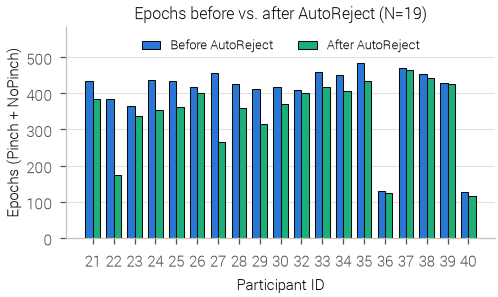

In [18]:
cmp_df2 = cmp_df.loc[[s for s in cmp_df.index if s in md['subject'].unique()]]
cmp_df2 = cmp_df2.sort_index(key=lambda s: [int(x.split('_')[1]) for x in s])

fig, ax = plt.subplots(figsize=(COL_W, 2.0))
x = np.arange(len(cmp_df2))
width = 0.35
ax.bar(x - width / 2, cmp_df2['n_pre'], width, color=CAT_COLORS[0], edgecolor=INK_PRIMARY, linewidth=0.5, label='Before AutoReject')
ax.bar(x + width / 2, cmp_df2['n_post'], width, color=CAT_COLORS[2], edgecolor=INK_PRIMARY, linewidth=0.5, label='After AutoReject')
ax.set_xticks(x)
ax.set_xticklabels([s.replace('subject_', '') for s in cmp_df2.index])
ax.set_xlabel('Participant ID')
ax.set_ylabel('Epochs (Pinch + NoPinch)')
ax.set_title(f'Epochs before vs. after AutoReject (N={len(cmp_df2)})')
ax.set_ylim(top=cmp_df2['n_pre'].max() * 1.2)  # room for the legend
ax.legend(frameon=False, loc='upper center', ncols=2)
ax.yaxis.grid(True)
ax.set_axisbelow(True)
clean_axes(ax)
fig.tight_layout(pad=0.3)
savefig(fig, 'dataset_before_after_autoreject.pdf')
plt.show()

**Figure: per-participant variability in the cleaned dataset.** Left: retained epoch count per participant. Right: mean (over epochs) worst-channel peak-to-peak amplitude per participant, in microvolts -- a raw-signal-level proxy for residual noise. Both vary severalfold across participants (e.g. subject_21's mean PTP is ~3x subject_32's), corroborating -- at the raw-data level -- the thesis's discussion of substantial subject-to-subject variability in downstream model accuracy (see the per-subject LOSO accuracy figure in `17_feedback_and_significance_analysis.ipynb`).

wrote C:\Users\nicol\github\VIBE\DataAnalysis\out\figs\persubject_variability.pdf


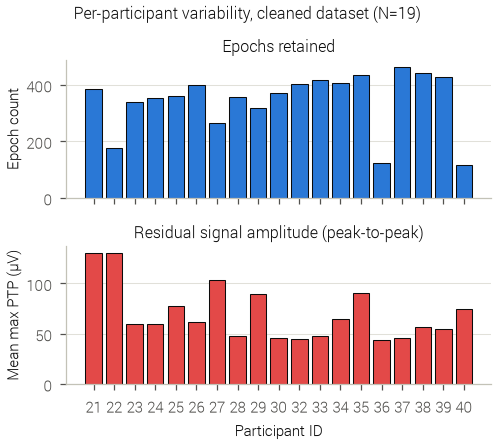

In [19]:
eeg_data_all = epochs.copy().pick('eeg').get_data() * 1e6  # (n_epochs, n_ch, n_times)
ptp = eeg_data_all.max(axis=2) - eeg_data_all.min(axis=2)   # (n_epochs, n_ch)
ptp_max = ptp.max(axis=1)                                   # worst channel per epoch, microvolts
md_ptp = md.copy()
md_ptp['ptp_uv'] = ptp_max

per_subj_count = md.groupby('subject').size()
per_subj_ptp = md_ptp.groupby('subject')['ptp_uv'].mean()
subj_order = sorted(per_subj_count.index, key=lambda s: int(s.split('_')[1]))

fig, axes = plt.subplots(2, 1, figsize=(COL_W, 3.0), sharex=True, layout='constrained')
ax = axes[0]
ax.bar([s.replace('subject_', '') for s in subj_order], per_subj_count.loc[subj_order],
       color=CAT_COLORS[0], edgecolor=INK_PRIMARY, linewidth=0.5)
ax.set_ylabel('Epoch count')
ax.set_title('Epochs retained')
ax.yaxis.grid(True)
ax.set_axisbelow(True)
clean_axes(ax)

ax = axes[1]
ax.bar([s.replace('subject_', '') for s in subj_order], per_subj_ptp.loc[subj_order],
       color=CAT_COLORS[7], edgecolor=INK_PRIMARY, linewidth=0.5)
ax.set_xlabel('Participant ID')
ax.set_ylabel('Mean max PTP (\u00b5V)')
ax.set_title('Residual signal amplitude (peak-to-peak)')
ax.yaxis.grid(True)
ax.set_axisbelow(True)
clean_axes(ax)
fig.suptitle(f'Per-participant variability, cleaned dataset (N={len(subj_order)})')
savefig(fig, 'persubject_variability.pdf')
plt.show()

**Figure: EEGNet LOSO accuracy vs. AutoReject drop rate, per participant.** Top left: accuracy of the EEGNet leave-one-subject-out model on each held-out participant (dashed line = mean majority-class chance). Bottom left: share of that participant's epochs dropped by AutoReject, counting only the `PINCH` + `Empty` epochs the cached LOSO run is trained and tested on (`FingerMovement` epochs were added to the dataset after that run and are excluded here) (`data/epoch_dataset` before vs. `data/epoch_dataset_filtered` after). Right: accuracy against drop rate, with an ordinary least-squares fit and Pearson / Spearman correlations (n = one point per participant). A drop rate normalizes for how many trials each participant recorded, so it measures data quality rather than data quantity.

*Based on: `out/results/eegnet_leave_one_out_run.pkl` (the base EEGNet LOSO run from `15_classification.ipynb`), per-fold accuracy computed the same way as `17_feedback_and_significance_analysis.ipynb`, Task 1; drop rate from the same lazily-read epoch metadata (`md_pre`, `md_post_lazy`) as the AutoReject rejection-rate figure in Part 1.*

            accuracy  chance  n_pre  n_post  drop_pct
subject                                              
subject_21    0.6480  0.5389    362     321   11.3260
subject_22    0.7039  0.6316    326     152   53.3742
subject_23    0.7372  0.5292    301     274    8.9701
subject_24    0.6655  0.5439    368     296   19.5652
subject_25    0.6786  0.5032    377     308   18.3024
subject_26    0.6394  0.5364    344     330    4.0698
subject_27    0.6205  0.5089    387     224   42.1189
subject_28    0.7543  0.5154    355     293   17.4648
subject_29    0.7453  0.5581    350     267   23.7143
subject_30    0.6461  0.5260    352     308   12.5000
subject_32    0.8119  0.5373    339     335    1.1799
subject_33    0.6912  0.5029    369     340    7.8591
subject_34    0.6207  0.5204    355     319   10.1408
subject_35    0.6484  0.5412    404     364    9.9010
subject_36    0.7556  0.5111     97      90    7.2165
subject_37    0.7399  0.5174    380     373    1.8421
subject_38    0.8039  0.5028

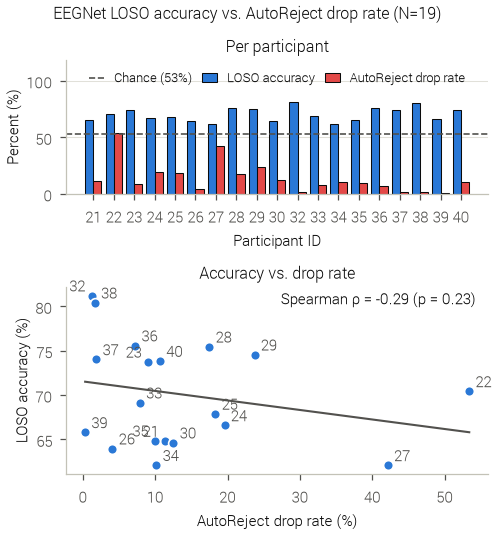

In [20]:
from scipy.stats import pearsonr, spearmanr

eegnet_loso = load_cached('eegnet_leave_one_out_run')

loso_rows = []
for subj, fold in eegnet_loso.items():
    y_true = fold['test_metadata']['EventType'].to_numpy()
    y_pred = np.asarray(fold['result']['y_pred'])
    assert len(y_true) == len(y_pred), f'{subj}: y_true/y_pred length mismatch'
    loso_rows.append(dict(
        subject=subj,
        accuracy=float((y_true == y_pred).mean()),
        n_test=len(y_true),
        chance=max((y_true == 'PinchLog').mean(), (y_true == 'NoPinchLog').mean()),
    ))
loso_subj = pd.DataFrame(loso_rows).set_index('subject')

# AutoReject drop rate on the same epoch subset the cached LOSO run uses: PINCH pinches + Empty
# negatives (FingerMovement epochs postdate that run, so they are left out)
def loso_subset_counts(m):
    keep = ((m['EventType'] == 'PinchLog') & (m['PinchType'] == 'PINCH')) |            ((m['EventType'] == 'NoPinchLog') & (m['PinchType'] == 'Empty'))
    return m[keep].groupby('subject').size()

loso_subj['n_pre'] = loso_subset_counts(md_pre)
loso_subj['n_post'] = loso_subset_counts(md_post_lazy)
loso_subj['drop_pct'] = 100 * (1 - loso_subj['n_post'] / loso_subj['n_pre'])
mismatch = loso_subj.index[loso_subj['n_post'] != loso_subj['n_test']].tolist()
if mismatch:
    print(f'WARNING: post-AutoReject counts differ from the LOSO test-fold sizes for {mismatch} '
          f'(epoch_dataset_filtered changed since the LOSO run?)')
loso_subj = loso_subj.sort_index(key=lambda s: [int(x.split('_')[1]) for x in s])

r_p, p_p = pearsonr(loso_subj['drop_pct'], loso_subj['accuracy'])
r_s, p_s = spearmanr(loso_subj['drop_pct'], loso_subj['accuracy'])
print(loso_subj[['accuracy', 'chance', 'n_pre', 'n_post', 'drop_pct']].round(4))
print(f'\nPearson r = {r_p:.3f} (p = {p_p:.3g}),  Spearman rho = {r_s:.3f} (p = {p_s:.3g}),  '
      f'n = {len(loso_subj)} participants')

ids = [s.replace('subject_', '') for s in loso_subj.index]
x = np.arange(len(loso_subj))
chance_mean = loso_subj['chance'].mean()

acc_pct = 100 * loso_subj['accuracy']
chance_pct = 100 * chance_mean

fig = plt.figure(figsize=(COL_W, 3.6), layout='constrained')
gs = fig.add_gridspec(2, 1, height_ratios=[1, 1.4])
ax_b = fig.add_subplot(gs[0])
ax_sc = fig.add_subplot(gs[1])

# accuracy and drop rate are both percentages, so they share one y axis
w = 0.4
ax_b.bar(x - w / 2, acc_pct, w, color=CAT_COLORS[0], edgecolor=INK_PRIMARY, linewidth=0.5, label='LOSO accuracy')
ax_b.bar(x + w / 2, loso_subj['drop_pct'], w, color=CAT_COLORS[7], edgecolor=INK_PRIMARY, linewidth=0.5,
         label='AutoReject drop rate')
ax_b.axhline(chance_pct, color=INK_SECONDARY, linestyle='--', linewidth=0.8, label=f'Chance ({chance_pct:.0f}%)')
ax_b.set_xticks(x)
ax_b.set_xticklabels(ids)
ax_b.set_xlabel('Participant ID')
ax_b.set_ylabel('Percent (%)')
ax_b.set_ylim(0, 118)  # headroom for the legend
ax_b.legend(frameon=False, loc='upper center', ncols=3, handlelength=1.2, columnspacing=0.8)
ax_b.set_title('Per participant')
ax_b.yaxis.grid(True)
ax_b.set_axisbelow(True)
clean_axes(ax_b)

ax_sc.scatter(loso_subj['drop_pct'], acc_pct, s=22, color=CAT_COLORS[0],
              edgecolor='white', linewidth=0.8, zorder=3)
slope, intercept = np.polyfit(loso_subj['drop_pct'], acc_pct, 1)
xs = np.linspace(loso_subj['drop_pct'].min(), loso_subj['drop_pct'].max(), 50)
ax_sc.plot(xs, slope * xs + intercept, color=INK_SECONDARY, linewidth=1, zorder=2)
# label each point with its participant ID; when another point sits just to its right (close
# enough that right-hand labels would collide), put this point's label on its left instead
x_close = 0.05 * (loso_subj['drop_pct'].max() - loso_subj['drop_pct'].min())
pts = list(zip(ids, loso_subj['drop_pct'], acc_pct))
for sid, d_, acc_ in pts:
    flip = any(0 < d2 - d_ < x_close and abs(a2 - acc_) < 1 for _, d2, a2 in pts)
    ax_sc.annotate(sid, (d_, acc_), xytext=(-3, 2) if flip else (3, 2), textcoords='offset points',
                   ha='right' if flip else 'left', color=INK_SECONDARY)
ax_sc.text(0.97, 0.99, f'Spearman \u03c1 = {r_s:.2f} (p = {p_s:.2f})',
           transform=ax_sc.transAxes, ha='right', va='top', color=INK_PRIMARY)
ax_sc.set_xlabel('AutoReject drop rate (%)')
ax_sc.set_ylabel('LOSO accuracy (%)')
ax_sc.set_title('Accuracy vs. drop rate')
clean_axes(ax_sc)

fig.suptitle(f'EEGNet LOSO accuracy vs. AutoReject drop rate (N={len(loso_subj)})')
savefig(fig, 'persubject_loso_accuracy_vs_droprate.pdf')
plt.show()

## Summary

All figures were written to `out/figs/`:

**Part 1 (recreations, paper style):**
1. `dataquality_session_duration.pdf` - mean recording duration by session
2. `dataquality_marker_counts.pdf` - mean marker volume by event type
3. `dataquality_pinchtype_counts.pdf` - mean pinch-event outcome by type (bug-fixed)
4. `dataquality_autoreject_droprate.pdf` - AutoReject rejection rate by participant (substitute for the structurally-empty bad-electrode panel)
5. `erp_pinch_vs_nopinch.pdf` - grand-average ERP, Pinch vs. No-Pinch, C3/Cz
6. `topomap_pinch_sequence.pdf` - topomap sequence, PINCH trials
7. `model_comparison_by_split.pdf` - model x split (Mixed/LOSO/Cross-Session) accuracy

**Part 2 (new figures):**
8. `freevar_erp_spn_smallmultiples.pdf` - visual/auditory feedback + virtual hand ERP comparison, each at the (up to five) SPN electrodes where that modality most enlarges the late SPN, small multiples
9. `freevar_epoch_counts.pdf` - class balance of the boolean free variables
10. `numberofstimuli_layout.pdf` - stimulus-layout size: counts + ERP by layout
11. `dataset_session1_vs_session2.pdf` - session 1 vs. 2: counts + class balance
12. `dataset_before_after_autoreject.pdf` - per-subject epoch counts, before vs. after AutoReject
13. `persubject_variability.pdf` - per-subject epoch counts + mean peak-to-peak amplitude
14. `persubject_loso_accuracy_vs_droprate.pdf` - per-subject EEGNet LOSO accuracy vs. AutoReject drop rate, with correlation